# Домашнее задание 1: сравнение пяти рекомендательных моделей на Amazon Reviews 2023 (Video Games)

**Как запустить**

```bash
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
jupyter nbconvert --to notebook --execute --inplace experiments.ipynb   # или Run All в Jupyter
```

Данные скачиваются автоматически первой ячейкой раздела 1 (функция `utils.data.download`) в `data/raw/`
(~0.5 ГБ, папка в `.gitignore`). Источник: Hou et al., *Bridging Language and Items for Retrieval and
Recommendation*, 2024 — <https://amazon-reviews-2023.github.io/>, файлы на HuggingFace
`McAuley-Lab/Amazon-Reviews-2023`: `benchmark/5core/rating_only/Video_Games.csv` и
`raw/meta_categories/meta_Video_Games.jsonl`.

Все случайные зёрна (`SEED`), параметры подвыборки и разбиения зафиксированы в ячейке ниже.
Модели реализованы с нуля в `models/` (NumPy/SciPy/PyTorch), общие функции — в `utils/`.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from utils.data import (download, load_ratings, load_meta, make_subsample, temporal_split,
                        Encoder, set_seed)
from utils.evaluation import build_eval_set, evaluate, paired_bootstrap
from utils.features import item_features, user_features
from utils.tuning import tune
from models import ItemKNN, IALS, EASE, FactorizationMachine, TimeSVDpp, Popularity

SEED = 42
K = 10
METRIC = "ndcg@10"      # основная метрика, выбрана до подбора
N_TRIALS = 25           # число триалов Optuna на модель
CONFIG = dict(start="2012-01-01", min_user=5, min_item=10, val_q=0.8, test_q=0.9, pos_threshold=4.0)

set_seed(SEED)
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110

## 1. Данные

**Amazon Reviews 2023, категория Video Games** (McAuley Lab, UCSD). Берём официальный 5-core
бенчмарк-файл с оценками и сырые метаданные товаров.

| поле | смысл |
|---|---|
| `user_id` | анонимный идентификатор покупателя Amazon |
| `parent_asin` → `item_id` | идентификатор товара (родительский ASIN, объединяет варианты) |
| `rating` | оценка 1–5 в отзыве |
| `timestamp` | время отзыва (Unix, переводим в секунды) |
| метаданные | `title`, `main_category`, `categories` (путь в каталоге: платформа → тип), `store` (издатель/бренд), `price`, `details` (ESRB-рейтинг `Rated`, дата выхода) |

**Взаимодействие** — отзыв с оценкой. Это прокси покупки: отзыв оставляют на купленный товар.

**Что рекомендуем:** персональный top-10 товаров категории Video Games (игры, консоли, аксессуары),
которые пользователь ещё не оценивал.

**Релевантный объект:** товар, который пользователь оценил в целевом временном окне
**на 4 или 5** («купил и остался доволен»). Этот критерий одинаков для всех моделей,
независимо от того, на каком сигнале модель обучается.

In [2]:
download("data/raw")
raw = load_ratings("data/raw")
meta_all = load_meta("data/raw", items=set(raw["item_id"]))
print("ratings:", raw.shape, " meta:", meta_all.shape)
display(raw.head())
display(meta_all.head(3))

ratings: (814586, 4)  meta: (25612, 10)


,user_id,item_id,rating,timestamp
0,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08R5B7YS4,1.0,1611459666
1,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0863MT183,4.0,1613701986
2,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B08P8P7686,5.0,1613702112
3,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B0B7LV3DN2,4.0,1617641445
4,AEVPPTMG43C6GWSR7I2UGRQN7WFQ,B09WMQ6DXG,5.0,1620231368


,item_id,title,main_category,categories,store,price,rated,year,has_description,n_features
0,B00Z9TLVK0,NBA 2K17 - Early Tip Off Edition - PlayStation 4,Video Games,"[Video Games, PlayStation 4, Games]",2K,58.00,Everyone,2016.0,True,10
1,B07H93H878,eXtremeRate Soft Touch Top Shell Front Housing...,Video Games,"[Video Games, Xbox One, Accessories, Faceplate...",eXtremeRate,17.59,NaN,2017.0,False,5
2,B00006969T,Konami Collector's Series: Castlevania & Contr...,Video Games,"[Video Games, PC, Games]",Square Enix,NaN,Everyone,2002.0,True,4


## 2. EDA и подготовка данных

### 2.1 Пропуски и дубликаты

In [3]:
print("Пропуски в рейтингах:\n", raw.isna().sum().to_dict())
print("Полные дубликаты строк:", raw.duplicated().sum())
print("Повторные пары (user, item):", raw.duplicated(["user_id", "item_id"]).sum())
miss = pd.Series({
    "title": meta_all["title"].isna().mean(),
    "store": meta_all["store"].isna().mean(),
    "price": meta_all["price"].isna().mean(),
    "rated (ESRB)": meta_all["rated"].isna().mean(),
    "year": meta_all["year"].isna().mean(),
    "categories пусто": (meta_all["categories"].str.len() == 0).mean(),
    "description пусто": (~meta_all["has_description"]).mean(),
}, name="доля пропусков")
display(miss.to_frame().style.format("{:.1%}"))

Пропуски в рейтингах:
 {'user_id': 0, 'item_id': 0, 'rating': 0, 'timestamp': 0}
Полные дубликаты строк: 0
Повторные пары (user, item): 0


,доля пропусков
title,0.0%
store,0.5%
price,33.1%
rated (ESRB),52.4%
year,3.8%
categories пусто,3.4%
description пусто,26.6%


### 2.2 Распределения: оценки, время, активность пользователей, популярность товаров

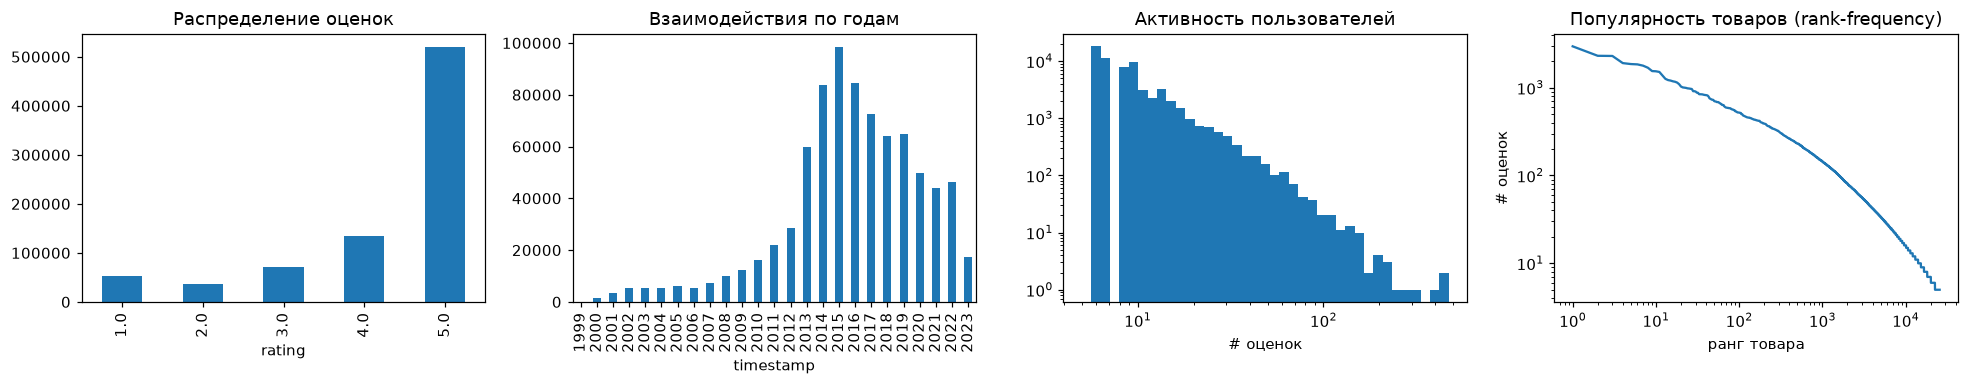

Доля оценок 4-5: 80.4%;  top-1% товаров дают 18.6% взаимодействий


In [4]:
def describe(df, name):
    nu, ni = df["user_id"].nunique(), df["item_id"].nunique()
    return pd.Series({"interactions": len(df), "users": nu, "items": ni,
                      "density": len(df) / (nu * ni),
                      "mean_user_len": len(df) / nu, "median_user_len": df.groupby("user_id").size().median(),
                      "mean_item_pop": len(df) / ni,
                      "start": pd.to_datetime(df["timestamp"].min(), unit="s").date(),
                      "end": pd.to_datetime(df["timestamp"].max(), unit="s").date()}, name=name)

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
raw["rating"].value_counts().sort_index().plot.bar(ax=ax[0], title="Распределение оценок")
pd.to_datetime(raw["timestamp"], unit="s").dt.year.value_counts().sort_index().plot.bar(ax=ax[1], title="Взаимодействия по годам")
ua = raw.groupby("user_id").size()
ax[2].hist(ua, bins=np.logspace(np.log10(5), np.log10(ua.max()), 40)); ax[2].set_xscale("log"); ax[2].set_yscale("log")
ax[2].set_title("Активность пользователей"); ax[2].set_xlabel("# оценок")
ip = raw.groupby("item_id").size().sort_values(ascending=False).values
ax[3].loglog(np.arange(1, len(ip) + 1), ip); ax[3].set_title("Популярность товаров (rank-frequency)")
ax[3].set_xlabel("ранг товара"); ax[3].set_ylabel("# оценок")
plt.tight_layout(); plt.show()
print(f"Доля оценок 4-5: {(raw.rating >= 4).mean():.1%};  top-1% товаров дают {ip[:len(ip)//100].sum()/ip.sum():.1%} взаимодействий")

Наблюдения: оценки сильно смещены к 5 (~64%), поэтому «оценка ≥ 4» — естественный порог
релевантности. Длинный хвост популярности: малая доля товаров собирает большую часть отзывов.
Активность пользователей тоже тяжёлохвостая: медиана — 6 оценок на пользователя.
Данные до 2012 года редкие (Amazon был другим магазином, в каталоге в основном legacy-платформы).

### 2.3 Очистка и подвыборка

1. **Удаляем повторные пары (user, item)**, оставляя последнюю. В 5-core файле их нет, шаг защитный.
2. **Оставляем взаимодействия с 2012-01-01.** Раньше данных мало, и они описывают другой ассортимент.
3. **Итеративный k-core: у пользователя ≥ 5 оценок, у товара ≥ 10.** Это убирает почти пустые
   строки и столбцы. Для EASE и ItemKNN важно, что число товаров уменьшается вдвое (25.6K → ~11K).
   Тогда матрица товар×товар помещается в память и обращается за секунды.
   Фильтрация детерминирована, поэтому подвыборка воспроизводима.

In [5]:
data = make_subsample(raw, CONFIG["start"], CONFIG["min_user"], CONFIG["min_item"])
summary = pd.concat([describe(raw, "исходный 5-core"), describe(data, "после фильтрации")], axis=1)
display(summary)
meta = meta_all[meta_all["item_id"].isin(set(data["item_id"]))].reset_index(drop=True)
assert 100_000 <= len(data) <= 2_000_000 and data.user_id.nunique() >= 1000 and data.item_id.nunique() >= 1000

,исходный 5-core,после фильтрации
interactions,814586,549975
users,94762,67007
items,25612,11192
density,0.000336,0.000733
mean_user_len,8.596125,8.207725
median_user_len,6.0,6.0
mean_item_pop,31.804857,49.140011
start,1999-10-22,2012-01-01
end,2023-09-02,2023-08-29


### 2.4 Анализ метаданных (на отфильтрованных товарах)

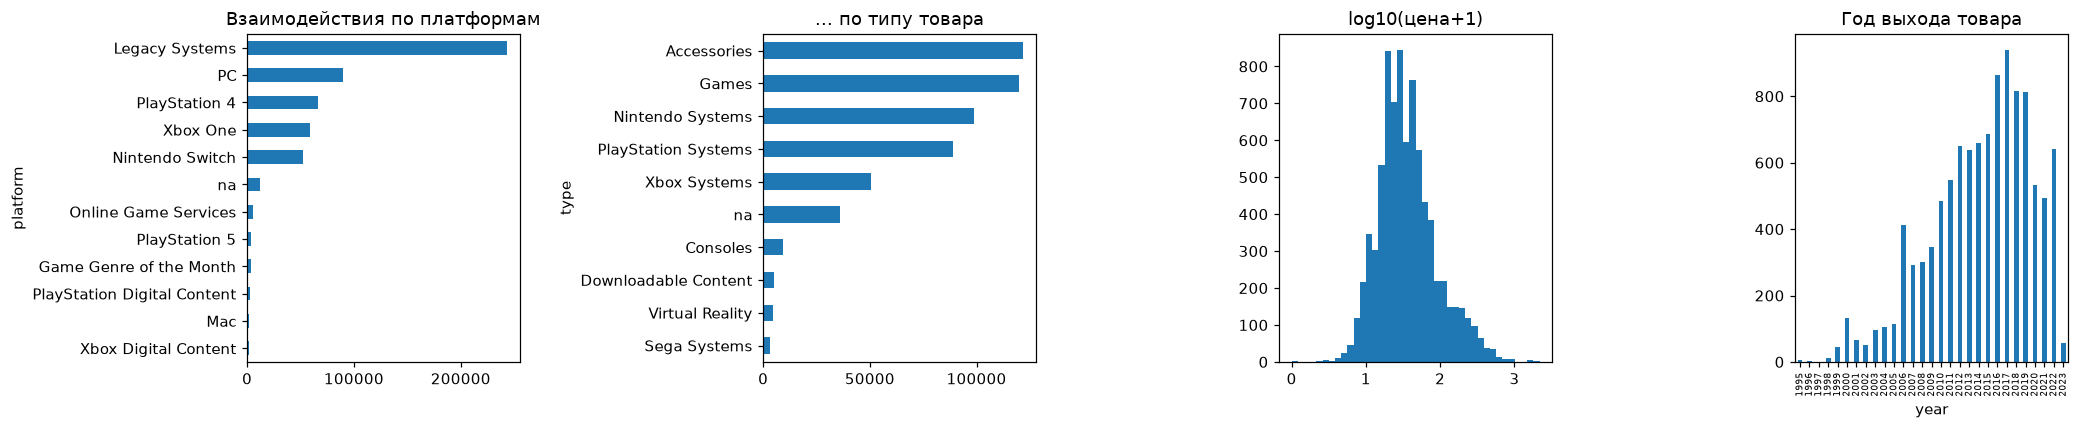

Уникальных store: 1790 ; top: {'Nintendo': 990, 'Electronic Arts': 434, 'PlayStation': 389, 'Microsoft': 332, 'ACTIVISION': 298, 'Ubisoft': 288, 'Square Enix': 229, 'BANDAI NAMCO Entertainment': 215}
ESRB: {'Everyone': 1628, 'Teen': 1395, 'Mature': 1166, 'Everyone 10+': 730, 'Rating Pending': 615, 'Kids to Adults': 34, 'Adults Only': 8, 'Early Childhood': 5}
Средняя оценка по типу товара:


,mean,size
type,,
Accessories,4.231,121715
Games,4.237,119901
Nintendo Systems,4.497,98741
PlayStation Systems,4.393,88829
Xbox Systems,4.336,50486
na,4.324,35791


In [6]:
meta["platform"] = meta["categories"].map(lambda c: c[1] if len(c) > 1 else "na")
meta["type"] = meta["categories"].map(lambda c: c[2] if len(c) > 2 else "na")
pop = data.groupby("item_id").size().rename("n")
m = meta.set_index("item_id").join(pop)

fig, ax = plt.subplots(1, 4, figsize=(19, 4))
m.groupby("platform")["n"].sum().sort_values().tail(12).plot.barh(ax=ax[0], title="Взаимодействия по платформам")
m.groupby("type")["n"].sum().sort_values().tail(10).plot.barh(ax=ax[1], title="... по типу товара")
ax[2].hist(np.log10(m["price"].dropna() + 1), bins=40); ax[2].set_title("log10(цена+1)")
m["year"].dropna().clip(1995, 2023).astype(int).value_counts().sort_index().plot.bar(ax=ax[3], title="Год выхода товара")
ax[3].tick_params(axis="x", labelsize=6)
plt.tight_layout(); plt.show()

print("Уникальных store:", m["store"].nunique(), "; top:", m["store"].value_counts().head(8).to_dict())
print("ESRB:", m["rated"].value_counts().head(8).to_dict())
print("Средняя оценка по типу товара:")
d2 = data.merge(meta[["item_id", "type", "platform"]], on="item_id")
display(d2.groupby("type")["rating"].agg(["mean", "size"]).sort_values("size", ascending=False).head(6).round(3))

Метаданные информативны для рекомендаций:
- **платформа** (PS4, Switch, PC, Xbox…) почти жёстко задаёт, что пользователь купит, потому что
  у него одна или две консоли;
- **тип** (игры / аксессуары / консоли) и **издатель** (`store`) задают вкус: франшизы Nintendo, EA Sports;
- **цена**, **ESRB** и **год выхода** отражают ценовой сегмент, аудиторию и «свежесть» товара.

Поля `average_rating`, `rating_number` и «Best Sellers Rank» — снимок на 2023 год, то есть информация
из будущего. Как признаки их **не используем**. Популярность и «возраст» товара пересчитываем
только по истории до момента рекомендации.

## 3. Протокол оценки

- **Разбиение — глобальное временное** по квантилям времени взаимодействий:
  train — первые 80%, validation — следующие 10%, test — последние 10%.
  Так моделируется реальный сценарий: рекомендации строятся в момент $t$ и проверяются на будущем.
- **Подбор гиперпараметров:** обучаем на train, оцениваем на validation.
  **Финальное сравнение:** с выбранными настройками переобучаем на train + validation
  и оцениваем на test. Test в подборе не участвует.
- **Релевантность:** взаимодействие в целевом окне с оценкой ≥ 4.
- **Пользователи оценки:** все пользователи с ≥ 1 релевантным товаром в окне и с непустой историей.
  **Новые (холодные) пользователи** без истории исключены: ни одна из моделей, кроме популярности,
  не может их ранжировать. Их доля указана ниже.
- **Кандидаты:** все товары, которые встречались в истории (train или train+val).
  **Новые товары**, впервые появившиеся в целевом окне, нельзя порекомендовать ни одной моделью,
  поэтому они убраны и из кандидатов, и из ground truth. Их доля тоже указана.
- **Исключение известного:** товары из истории пользователя удаляются из выдачи.
- Все модели ранжируют **один и тот же** набор кандидатов для **одних и тех же** пользователей.

In [7]:
split = temporal_split(data, CONFIG["val_q"], CONFIG["test_q"])
enc = Encoder(data, meta)
td_val = enc.train_data(split.train, t_pred=split.t_val)
es_val = build_eval_set(enc, td_val, split.val, CONFIG["pos_threshold"])
history_test = pd.concat([split.train, split.val])
td_test = enc.train_data(history_test, t_pred=split.t_test)
es_test = build_eval_set(enc, td_test, split.test, CONFIG["pos_threshold"])

def d(ts): return pd.to_datetime(ts, unit="s").date()
proto = pd.DataFrame({
    "окно": [f"{d(data.timestamp.min())} – {d(split.t_val)}", f"{d(split.t_val)} – {d(split.t_test)}", f"{d(split.t_test)} – {d(data.timestamp.max())}"],
    "взаимодействий": [len(split.train), len(split.val), len(split.test)],
    "позитивов (≥4)": [(split.train.rating >= 4).sum(), (split.val.rating >= 4).sum(), (split.test.rating >= 4).sum()],
    "польз. в оценке": ["—", len(es_val.users), len(es_test.users)],
    "релевантных пар в оценке": ["—", es_val.gt.nnz, es_test.gt.nnz],
    "позитивов холодных польз.": ["—", es_val.n_dropped_cold_users, es_test.n_dropped_cold_users],
    "позитивов холодных товаров": ["—", es_val.n_dropped_cold_items, es_test.n_dropped_cold_items],
    "кандидатов": ["—", int(td_val.item_mask.sum()), int(td_test.item_mask.sum())],
}, index=["train", "validation", "test"])
display(proto)

,окно,взаимодействий,позитивов (≥4),польз. в оценке,релевантных пар в оценке,позитивов холодных польз.,позитивов холодных товаров,кандидатов
train,2012-01-01 – 2019-11-18,439980,363666,—,—,—,—,—
validation,2019-11-18 – 2021-04-24,54997,44467,12361,23855,13440,7172,9346
test,2021-04-24 – 2023-08-29,54998,43640,10144,19428,13070,11142,10215


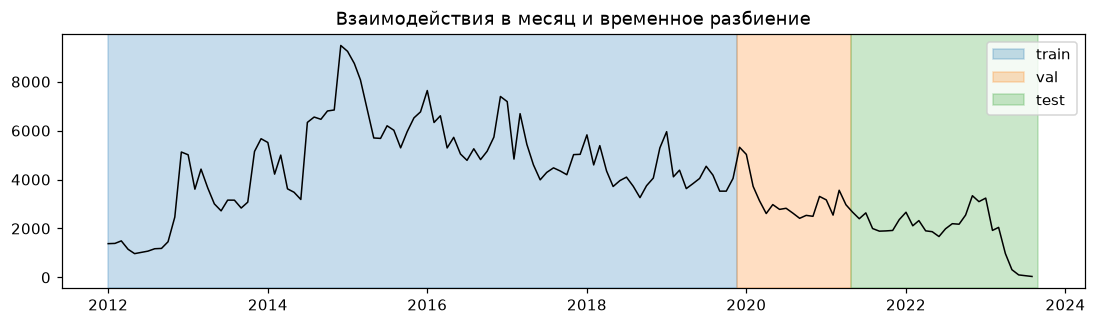

In [8]:
fig, ax = plt.subplots(figsize=(12, 3))
w = pd.to_datetime(data["timestamp"], unit="s").dt.to_period("M").value_counts().sort_index()
w.index = w.index.to_timestamp()
ax.plot(w.index, w.values, color="k", lw=1)
for a, b, c, l in [(data.timestamp.min(), split.t_val, "C0", "train"), (split.t_val, split.t_test, "C1", "val"), (split.t_test, data.timestamp.max(), "C2", "test")]:
    ax.axvspan(pd.to_datetime(a, unit="s"), pd.to_datetime(b, unit="s"), color=c, alpha=.25, label=l)
ax.set_title("Взаимодействия в месяц и временное разбиение"); ax.legend(); plt.show()

Заметная доля позитивов в окнах приходится на холодных пользователей и новые товары.
Это ограничение постановки: такие случаи решаются контентными и popularity-моделями.
Ниже сравниваются **тёплые** пользователи и **известные** товары.

## 4. Модели и подбор гиперпараметров

**Основная метрика — NDCG@10**, выбрана до подбора. Она учитывает позицию релевантного товара в
выдаче: в ленте рекомендаций первые позиции важнее. Дополнительно считаем Recall@10, HitRate@10,
MRR@10 и покрытие каталога.

Краткие постановки и формулы (подробнее — в docstring каждого файла `models/*.py`):

**1. ItemKNN** (`models/item_knn.py`). Сходство товаров — косинус с shrinkage:
$s_{ij} = \frac{\langle x_i, x_j\rangle}{\|x_i\|\|x_j\| + \lambda}$. Для каждого товара оставляем $k$ ближайших соседей.
Скор: $\hat r_{uj} = \sum_{i \in I(u)} x_{ui}\, s_{ji}$. Варианты весов $x_{ui}$: бинарный, оценка, idf пользователя.

**2. iALS** (`models/ials.py`, Hu–Koren–Volinsky). Задача — неявная обратная связь (сравниваем top-N по факту
взаимодействия): $\min \sum_{u,i} c_{ui}(p_{ui} - x_u^\top y_i)^2 + \lambda(\|X\|^2+\|Y\|^2)$,
$p_{ui} = [\text{наблюдалось}]$, $c_{ui} = 1 + \alpha w_{ui}$. Попеременно решаем
$(Y^\top Y + Y^\top(C_u - I)Y + \lambda I)x_u = Y^\top C_u p_u$ методом сопряжённых градиентов.

**3. EASE** (`models/ease.py`, Steck 2019). $\min_B \|X - XB\|_F^2 + \lambda\|B\|_F^2$, $\operatorname{diag}B = 0$.
Замкнутая форма: $P = (X^\top X + \lambda I)^{-1}$, $B_{ij} = -P_{ij}/P_{jj}$.

**4. FM с метапризнаками** (`models/fm.py`, Rendle 2010).
$\hat y(x) = w_0 + \sum_k w_k x_k + \sum_{k<l}\langle v_k, v_l\rangle x_k x_l$, обучение — BPR
$-\sum \log\sigma(\hat y_{ui} - \hat y_{uj})$ с равномерными негативами. Признаки:
- *пользователь*: id; профиль платформ из истории (доли); бакет средней оценки; бакет активности;
- *товар (статичные)*: id; все уровни пути категорий; `main_category`; издатель (`store`, редкие → other);
  ценовой квинтиль; ESRB; бакет года выхода;
- *товар (динамические, признаки взаимодействия)*: число взаимодействий за 90 дней до $t$ (лог-бакет)
  и возраст товара на момент $t$ (дней с первого взаимодействия).

Обоснование: взаимодействие *профиль платформ × платформа товара* отражает «какая у меня консоль»,
*издатель × история* — франшизы, популярность и возраст — тренд на новинки.

**Только информация, доступная в момент рекомендации.** Все пользовательские и динамические товарные
признаки считаются **point-in-time**. Для обучающей пары $(u, i, t)$ берётся профиль $u$ и популярность $i$
строго до $t$, для негатива — популярность $j$ на тот же $t$. При рекомендации признаки берутся на $t_{\text{pred}}$.
Первая версия считала их один раз на $t_{\text{pred}}$ для всех пар. Это утечка: в популярность входит сам
позитив, а в профиль — будущие покупки. С утечкой метаданные *ухудшали* FM (см. абляцию в 5.2).

**5. timeSVD++** (`models/timesvdpp.py`, Koren 2009). Явные оценки + время:
$\hat r_{ui}(t) = \mu + b_u + \alpha_u \mathrm{dev}_u(t) + b_{u,t} + b_i + b_{i,\mathrm{Bin}(t)} + q_i^\top\big(p_u + \alpha_{pu}\mathrm{dev}_u(t) + |N(u)|^{-1/2}\sum_{j\in N(u)} y_j\big)$,
$\mathrm{dev}_u(t) = \mathrm{sign}(t - t_u)|t-t_u|^{\beta}$, нормирован на своё std по train.
После последней оценки пользователя дрейф не экстраполируем: $t := \min(t, t^{\text{last}}_u)$.
Минимизируем MSE + L2, с отдельными коэффициентами для статичных параметров, временных ($\alpha$, $b_{i,\text{Bin}}$)
и дневного смещения $b_{u,t}$. Без раздельной регуляризации временные члены «запоминали» train (MSE ≈ 0.1).
Для top-N ранжируем по $\hat r_{ui}(t_{\text{pred}})$: $b_{u,t}$ для будущего дня неизвестен (= 0),
бин — последний.

В качестве ориентира добавлен бейзлайн **Popularity** — популярность за последние $w$ дней.

Пространства поиска (TPE, `N_TRIALS` триалов, seed = 42):

In [9]:
SPACES = {
    "Popularity": (Popularity, lambda t: {"window_days": t.suggest_categorical("window_days", [14, 30, 60, 90, 180, 365, None])}, {}),
    "ItemKNN": (ItemKNN, lambda t: {"k": t.suggest_int("k", 10, 3000, log=True),
                                    "shrink": t.suggest_float("shrink", 0.0, 200.0),
                                    "weighting": t.suggest_categorical("weighting", ["binary", "rating", "idf"])}, {}),
    "iALS": (IALS, lambda t: {"factors": t.suggest_categorical("factors", [32, 64, 128, 256]),
                              "reg": t.suggest_float("reg", 1e-1, 1e4, log=True),
                              "alpha": t.suggest_float("alpha", 0.1, 100.0, log=True),
                              "epochs": t.suggest_int("epochs", 5, 20),
                              "confidence": t.suggest_categorical("confidence", ["binary", "rating", "log"])}, {"seed": SEED}),
    "EASE": (EASE, lambda t: {"lam": t.suggest_float("lam", 10.0, 1e6, log=True),
                              "binary": t.suggest_categorical("binary", [True, False])}, {}),
    "FM": (FactorizationMachine, lambda t: {"factors": t.suggest_categorical("factors", [32, 64, 128]),
                                           "lr": t.suggest_float("lr", 3e-4, 1e-2, log=True),
                                           "reg": t.suggest_float("reg", 1e-6, 1e-2, log=True),
                                           "epochs": t.suggest_int("epochs", 2, 20)}, {"use_meta": True, "seed": SEED}),
    "timeSVD++": (TimeSVDpp, lambda t: {"factors": t.suggest_categorical("factors", [16, 32, 64]),
                                        "lr": t.suggest_float("lr", 1e-3, 1e-2, log=True),
                                        "reg": t.suggest_float("reg", 1e-3, 1.0, log=True),
                                        "reg_time": t.suggest_float("reg_time", 1e-2, 10.0, log=True),
                                        "reg_day": t.suggest_float("reg_day", 1e-1, 100.0, log=True),
                                        "epochs": t.suggest_int("epochs", 2, 20),
                                        "n_bins": t.suggest_categorical("n_bins", [10, 30, 60])}, {"use_time": True, "seed": SEED}),
}
pd.DataFrame({"пространство": {
    "Popularity": "window_days ∈ {14,30,60,90,180,365,all}",
    "ItemKNN": "k ∈ [10,3000] log; shrink ∈ [0,200]; weighting ∈ {binary, rating, idf}",
    "iALS": "factors ∈ {32..256}; reg ∈ [1e-1,1e4] log; alpha ∈ [0.1,100] log; epochs ∈ [5,20]; confidence ∈ {binary, rating, log}",
    "EASE": "lambda ∈ [10,1e6] log; binary ∈ {True, False}",
    "FM": "factors ∈ {32,64,128}; lr ∈ [3e-4,1e-2] log; reg ∈ [1e-6,1e-2] log; epochs ∈ [2,20]",
    "timeSVD++": "factors ∈ {16,32,64}; lr ∈ [1e-3,1e-2] log; reg ∈ [1e-3,1] log; reg_time ∈ [1e-2,10] log; reg_day ∈ [0.1,100] log; epochs ∈ [2,20]; n_bins ∈ {10,30,60}",
}})

,пространство
Popularity,"window_days ∈ {14,30,60,90,180,365,all}"
ItemKNN,"k ∈ [10,3000] log; shrink ∈ [0,200]; weighting..."
iALS,"factors ∈ {32..256}; reg ∈ [1e-1,1e4] log; alp..."
EASE,"lambda ∈ [10,1e6] log; binary ∈ {True, False}"
FM,"factors ∈ {32,64,128}; lr ∈ [3e-4,1e-2] log; r..."
timeSVD++,"factors ∈ {16,32,64}; lr ∈ [1e-3,1e-2] log; re..."


In [10]:
best, trials = {}, {}
for name, (cls, space, fixed) in SPACES.items():
    t0 = time.time()
    n = 7 if name == "Popularity" else N_TRIALS
    best[name], trials[name] = tune(cls, space, td_val, es_val, n_trials=n, metric=METRIC, seed=SEED, fixed=fixed)
    print(f"{name:10s} best val {METRIC} = {trials[name][METRIC].max():.4f}  ({time.time() - t0:.0f}s)  {best[name]}")

Popularity best val ndcg@10 = 0.0278  (5s)  {'window_days': 30}


ItemKNN    best val ndcg@10 = 0.0161  (58s)  {'k': 1945, 'shrink': 153.16953758907076, 'weighting': 'binary'}


iALS       best val ndcg@10 = 0.0182  (210s)  {'factors': 256, 'reg': 1422.7510780605146, 'alpha': 43.22730510068199, 'epochs': 16, 'confidence': 'log', 'seed': 42}


EASE       best val ndcg@10 = 0.0177  (508s)  {'lam': 952830.1852319884, 'binary': False}


FM         best val ndcg@10 = 0.0352  (630s)  {'factors': 128, 'lr': 0.000571441734036803, 'reg': 2.7620276753420587e-06, 'epochs': 16, 'use_meta': True, 'seed': 42}


timeSVD++  best val ndcg@10 = 0.0055  (349s)  {'factors': 32, 'lr': 0.001044004209938374, 'reg': 0.3413622723109348, 'reg_time': 0.20367759419359244, 'reg_day': 35.37702737187838, 'epochs': 11, 'n_bins': 60, 'use_time': True, 'seed': 42}


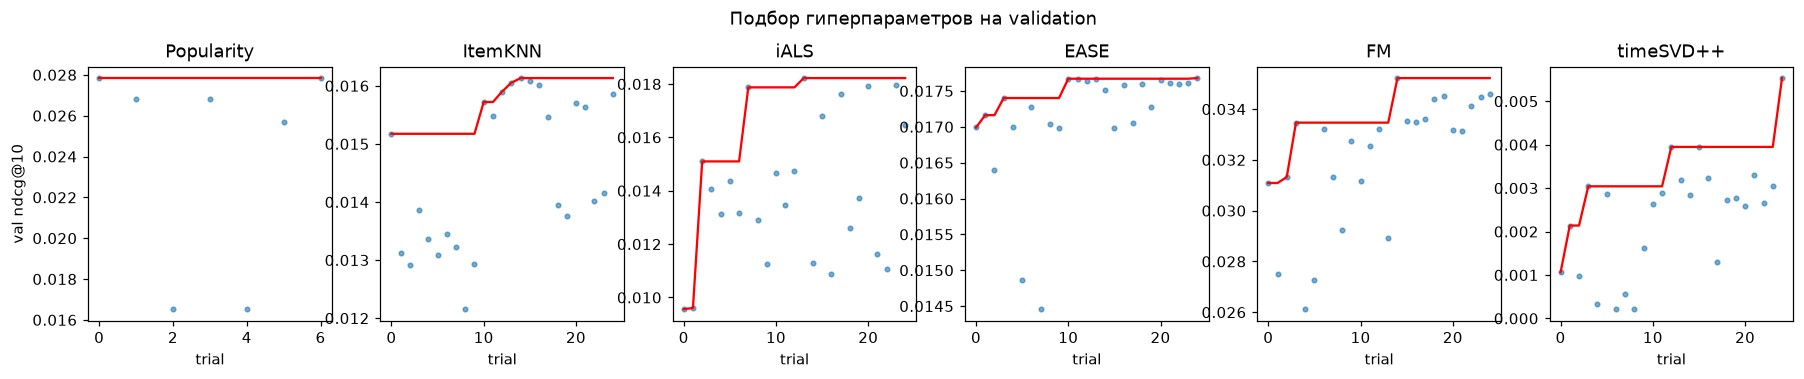

ItemKNN


,k,shrink,weighting,ndcg@10,recall@10,hit_rate@10,mrr@10,coverage@10,time_s
14,1945,153.1695,binary,0.0161,0.0250,0.0466,0.0195,0.6158,3.1180
15,2745,134.6994,binary,0.0161,0.0247,0.0459,0.0194,0.6255,3.4440
13,2629,166.4210,binary,0.0161,0.0248,0.0462,0.0193,0.6074,3.4209
16,2337,117.2299,binary,0.0160,0.0248,0.0459,0.0191,0.6398,3.2470
12,2079,174.1057,binary,0.0159,0.0247,0.0460,0.0191,0.6057,3.2240


EASE


,lam,binary,ndcg@10,recall@10,hit_rate@10,mrr@10,coverage@10,time_s
24,952830.1852,False,0.0177,0.0275,0.0520,0.0214,0.4782,20.2473
10,864414.0212,False,0.0177,0.0275,0.0520,0.0214,0.4784,19.8713
13,721978.0078,False,0.0177,0.0274,0.0519,0.0214,0.4793,20.5396
11,704183.0285,False,0.0177,0.0274,0.0519,0.0214,0.4797,20.3398
20,820456.6742,False,0.0177,0.0274,0.0519,0.0214,0.4787,20.7937


iALS


,factors,reg,alpha,epochs,confidence,seed,ndcg@10,recall@10,hit_rate@10,mrr@10,coverage@10,time_s
13,256,1422.7511,43.2273,16,log,42,0.0182,0.0265,0.0511,0.0234,0.0118,12.5174
23,256,890.2009,49.0112,10,binary,42,0.0180,0.0256,0.0506,0.0232,0.0164,7.8917
20,256,743.1896,30.3703,12,binary,42,0.0179,0.0260,0.0504,0.0230,0.0085,9.2084
7,256,342.2053,15.3823,17,rating,42,0.0179,0.0257,0.0502,0.0229,0.0141,12.6876
17,256,242.1532,6.7177,17,binary,42,0.0176,0.0260,0.0514,0.0226,0.0062,13.4729


In [11]:
fig, axes = plt.subplots(1, len(trials), figsize=(20, 3))
for ax, (name, tr) in zip(axes, trials.items()):
    ax.plot(tr[METRIC].values, "o", ms=3, alpha=.6); ax.plot(tr[METRIC].cummax().values, "r-")
    ax.set_title(name); ax.set_xlabel("trial")
axes[0].set_ylabel(f"val {METRIC}")
plt.suptitle("Подбор гиперпараметров на validation", y=1.05); plt.show()
for name in ["ItemKNN", "EASE", "iALS"]:
    print(name); display(trials[name].sort_values(METRIC, ascending=False).head(5).round(4))

## 5. Финальное сравнение на test

Модели с выбранными гиперпараметрами переобучаются на train + validation (история до начала test)
и оцениваются на test по тому же протоколу.

In [12]:
final, per_user, recs_all, val_res = {}, {}, {}, {}
for name, (cls, _, _) in SPACES.items():
    val_res[name] = trials[name].sort_values(METRIC, ascending=False).iloc[0][[c for c in trials[name].columns if "@" in c]].to_dict()
    model = cls(**best[name]).fit(td_test)
    final[name], per_user[name], recs_all[name] = evaluate(model, td_test, es_test, K, return_per_user=True)
    if name == "FM": fm_model = model
    if name == "timeSVD++": tsvd_model = model

order = ["ItemKNN", "iALS", "EASE", "FM", "timeSVD++", "Popularity"]
results = pd.DataFrame(final).T.loc[order]
results.insert(0, f"val {METRIC}", [val_res[n][METRIC] for n in order])
results["гиперпараметры"] = [", ".join(f"{k}={round(v, 4) if isinstance(v, float) else v}" for k, v in best[n].items() if k != "seed") for n in order]
display(results.style.format({c: "{:.4f}" for c in results.columns if "@" in c}).background_gradient(subset=[c for c in results.columns if c.startswith("ndcg") or c.startswith("recall")], cmap="Greens"))

,val ndcg@10,ndcg@10,recall@10,hit_rate@10,mrr@10,coverage@10,гиперпараметры
ItemKNN,0.0161,0.0133,0.0216,0.0400,0.0155,0.5427,"k=1945, shrink=153.1695, weighting=binary"
iALS,0.0182,0.0126,0.0198,0.0388,0.0150,0.0098,"factors=256, reg=1422.7511, alpha=43.2273, epochs=16, confidence=log"
EASE,0.0177,0.0136,0.0227,0.0431,0.0156,0.4063,"lam=952830.1852, binary=False"
FM,0.0352,0.0250,0.0445,0.0761,0.0261,0.0379,"factors=128, lr=0.0006, reg=0.0, epochs=16, use_meta=True"
timeSVD++,0.0055,0.0051,0.0094,0.0184,0.0050,0.1727,"factors=32, lr=0.001, reg=0.3414, reg_time=0.2037, reg_day=35.377, epochs=11, n_bins=60, use_time=True"
Popularity,0.0278,0.0172,0.0371,0.0653,0.0152,0.0017,window_days=30


### 5.1 Значимость различий (парный бутстрэп по пользователям, 95% ДИ для разности NDCG@10)

In [13]:
ref = results.drop(index="Popularity")["ndcg@10"].idxmax()
rows = []
for n in order:
    if n == ref: continue
    m, lo, hi = paired_bootstrap(per_user[ref]["ndcg"].values, per_user[n]["ndcg"].values, seed=SEED)
    rows.append({"сравнение": f"{ref} − {n}", "ΔNDCG@10": m, "ДИ 2.5%": lo, "ДИ 97.5%": hi, "значимо": lo > 0 or hi < 0})
display(pd.DataFrame(rows).round(4))

,сравнение,ΔNDCG@10,ДИ 2.5%,ДИ 97.5%,значимо
0,FM − ItemKNN,0.0117,0.0093,0.0141,True
1,FM − iALS,0.0124,0.0101,0.0148,True
2,FM − EASE,0.0114,0.0091,0.0139,True
3,FM − timeSVD++,0.0199,0.0178,0.0222,True
4,FM − Popularity,0.0078,0.0056,0.0100,True


### 5.2 Влияние метаданных (FM) и временных компонент (timeSVD++)

Абляции с **теми же** гиперпараметрами и тем же протоколом:
- FM: полная; без динамических товарных признаков; без пользовательских признаков; только id
  (`use_meta=False`); только метапризнаки, без id; полная, но с **признаками на $t_{\text{pred}}$ для всех пар**
  (версия с утечкой, для иллюстрации);
- SVD++ — timeSVD++ без временных компонент (`use_time=False`).

Для timeSVD++ дополнительно считаем RMSE предсказания оценок на test: это его «родная» задача.

In [14]:
abl = {}
class FMLeaky(FactorizationMachine):
    # абляция: признаки посчитаны один раз на t_pred и подставлены во все обучающие пары
    def _build(self, td):
        super()._build(td)
        self.Fu_pairs = self.Fu[torch.from_numpy(td.df["uid"].values)]
        dyn = self.dyn
        self.dyn = lambda i, t: dyn(i, np.full(len(i), td.t_pred))

import torch
fm_variants = [("FM (полная)", FactorizationMachine, {}),
               ("FM без динамических товарных", FactorizationMachine, {"use_dynamic": False}),
               ("FM без пользовательских", FactorizationMachine, {"use_user_meta": False}),
               ("FM только id", FactorizationMachine, {"use_meta": False}),
               ("FM только meta (без id)", FactorizationMachine, {"use_ids": False}),
               ("FM с утечкой (признаки на t_pred)", FMLeaky, {})]
for label, cls_, kw in fm_variants:
    params = {**best["FM"], **kw}
    for split_name, td_, es_ in [("val", td_val, es_val), ("test", td_test, es_test)]:
        m = cls_(**params).fit(td_)
        abl[(label, split_name)] = evaluate(m, td_, es_)
for label, kw in [("timeSVD++", {}), ("SVD++ (без времени)", {"use_time": False})]:
    params = {**best["timeSVD++"], **kw}
    for split_name, td_, es_ in [("val", td_val, es_val), ("test", td_test, es_test)]:
        m = TimeSVDpp(**params).fit(td_)
        res = evaluate(m, td_, es_)
        # RMSE на всех тёплых парах целевого окна (все оценки, не только ≥4)
        tgt = enc.encode(split.val if split_name == "val" else split.test)
        warm = (td_.X.getnnz(axis=1)[tgt.uid] > 0) & td_.item_mask[tgt.iid]
        tgt = tgt[warm]
        pred = m.predict(tgt.uid.values, tgt.iid.values, tgt.timestamp.values / 86400.0)
        res["RMSE"] = float(np.sqrt(np.mean((np.clip(pred, 1, 5) - tgt.rating.values) ** 2)))
        abl[(label, split_name)] = res
abl = pd.DataFrame(abl).T
abl.index.names = ["модель", "окно"]
display(abl[["ndcg@10", "recall@10", "hit_rate@10", "coverage@10", "RMSE"]].round(4))

ndcg@10  recall@10  hit_rate@10  coverage@10    RMSE
модель                            окно                                                      
FM (полная)                       val    0.0352     0.0613       0.1025       0.0337     NaN
                                  test   0.0250     0.0445       0.0761       0.0379     NaN
FM без динамических товарных      val    0.0175     0.0273       0.0523       0.0462     NaN
                                  test   0.0121     0.0192       0.0375       0.0513     NaN
FM без пользовательских           val    0.0314     0.0554       0.0944       0.0250     NaN
                                  test   0.0210     0.0391       0.0672       0.0282     NaN
FM только id                      val    0.0167     0.0252       0.0493       0.1484     NaN
                                  test   0.0128     0.0216       0.0406       0.1359     NaN
FM только meta (без id)           val    0.0266     0.0492       0.0811       0.0074     NaN
                                  test   0.0160     0.0312       0.0550       0.0088     NaN
FM с утечкой (признаки на t_pred) val    0.0122     0.0192       0.0366       0.0695     NaN
                                  test   0.0093     0.0155       0.0317       0.0699     NaN
timeSVD++                         val    0.0055     0.0109       0.0197       0.1813  1.2440
                                  test   0.0051     0.0094       0.0184       0.1727  1.3077
SVD++ (без времени)               val    0.0003     0.0006       0.0011       0.0781  1.2240
                                  test   0.0011     0.0019       0.0030       0.0674  1.2877

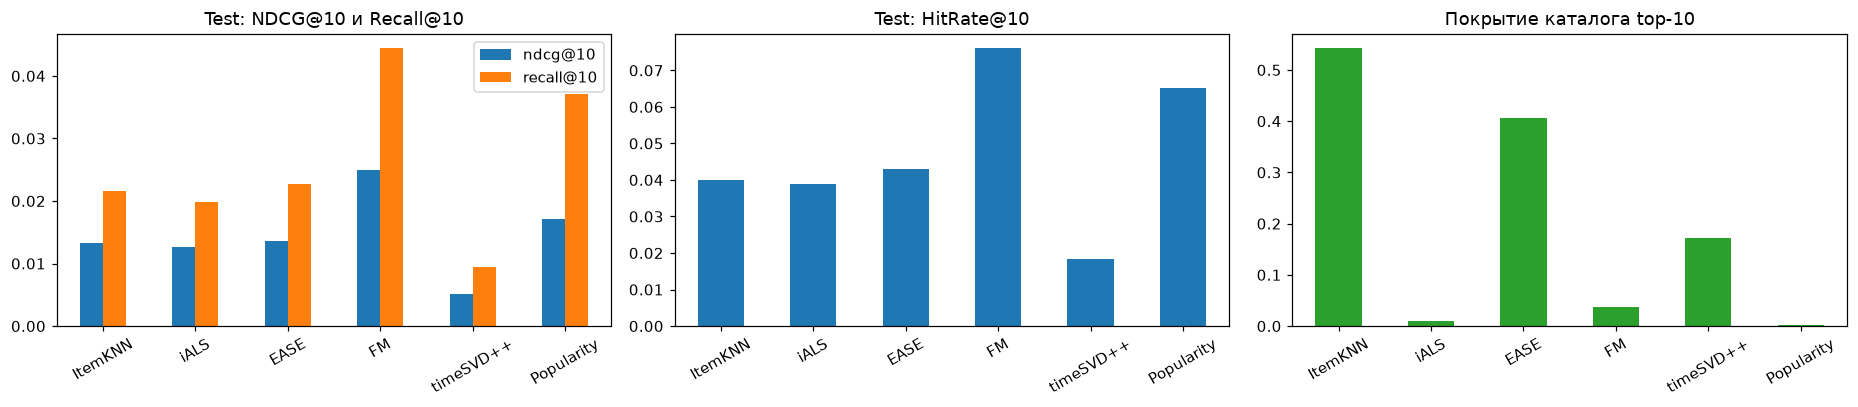

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(17, 3.8))
results[["ndcg@10", "recall@10"]].plot.bar(ax=ax[0], rot=30, title="Test: NDCG@10 и Recall@10")
results[["hit_rate@10"]].plot.bar(ax=ax[1], rot=30, title="Test: HitRate@10", legend=False)
results[["coverage@10"]].plot.bar(ax=ax[2], rot=30, title="Покрытие каталога top-10", legend=False, color="C2")
plt.tight_layout(); plt.show()

### 5.3 Качество по сегментам активности пользователей (test, NDCG@10)

In [16]:
hist_len = np.asarray(td_test.X.getnnz(axis=1))[es_test.users]
seg = pd.cut(hist_len, [0, 5, 10, 20, 10_000], labels=["≤5", "6–10", "11–20", ">20"])
seg_tab = pd.DataFrame({n: per_user[n]["ndcg"].groupby(seg, observed=True).mean() for n in order})
seg_tab["# польз."] = pd.Series(seg).value_counts().reindex(seg_tab.index)
display(seg_tab.round(4))

,ItemKNN,iALS,EASE,FM,timeSVD++,Popularity,# польз.
≤5,0.0143,0.0133,0.0144,0.0261,0.0048,0.0170,6316
6–10,0.0111,0.0124,0.0125,0.0226,0.0048,0.0188,2506
11–20,0.0125,0.0101,0.0104,0.0214,0.0065,0.0134,955
>20,0.0126,0.0081,0.0156,0.0312,0.0074,0.0192,367


### 5.4 Пример рекомендаций

In [17]:
rng = np.random.default_rng(SEED)
r = int(rng.integers(len(es_test.users)))
u = es_test.users[r]
titles = enc.meta["title"].fillna("?").str.slice(0, 60).values
hist = td_test.df[td_test.df.uid == u].sort_values("timestamp").tail(8)
print("История (последние 8):"); [print("  ", titles[i], f"({int(x)}★)") for i, x in zip(hist.iid, hist.rating)]
rel = set(es_test.gt.indices[es_test.gt.indptr[r]:es_test.gt.indptr[r + 1]])
print("Релевантные в test:", [titles[i] for i in rel])
show = pd.DataFrame({n: [("✔ " if i in rel else "") + titles[i] for i in recs_all[n][r]] for n in ["EASE", "FM", "timeSVD++"]})
display(show)

История (последние 8):
   HORI Nintendo Switch Alumi Case (Mario Edition) Officially L (5★)
   eXtremeRate Soft Touch Grip Classics NES Style Console Back  (5★)
   Hori Nintendo Switch D-Pad Controller (L) (Pokemon: Black &  (5★)
   ipega PG-9163 N-Switch Gamepad Controller Handle Plug and Pl (5★)
Релевантные в test: ['Dockable Case for Nintendo Switch, Protective Case for Ninte']


,EASE,FM,timeSVD++
0,amFilm Tempered Glass Screen Protector for Nin...,Dockable Case for Nintendo Switch - Mumba TPU ...,TotalMount for Nintendo Switch – Mounts Ninten...
1,Nintendo Switch Pro Controller,Nintendo Switch with Neon Blue and Neon Red Jo...,Granblue Fantasy: Versus - Premium Edition - P...
2,"SanDisk 128GB microSDXC-Card, Licensed for Nin...",Super Mario 3D World + Bowser's Fury - Nintend...,Daydayup Switch Case Compatible with Nintendo ...
3,Super Mario Odyssey - Nintendo Switch,Nintendo Switch Lite - Blue with SanDisk 128GB...,HD Retrovision PlayStation 2/3 (PS2/PS3) Premi...
4,Luigi's Mansion 3 - Nintendo Switch [Digital C...,"SanDisk 128GB microSDXC-Card, Licensed for Nin...",ATLIN Gamebit Screwdriver Set 4.5mm and 3.8mm ...
5,8Bitdo Wireless USB Adapter 2 for Switch/Switc...,PowerA Enhanced Wireless Controller for Ninten...,$25 PlayStation Store Gift Card [Digital Code]
6,BASSTOP Portable DIY Replacement Housing Shell...,"8BitDo Pro 2 Bluetooth Controller for Switch, ...","Switch Dock Charger Adapter for Switch OLED, 3..."
7,Satisfye – ZenGrip Pro Gen 3 OLED Elite Bundle...,HORI Nintendo Switch Split Pad Pro (Pokemon Le...,"SanDisk 128GB microSDXC-Card, Licensed for Nin..."
8,8Bitdo Sn30 Pro+ Bluetooth Controller Wireless...,Ring Fit Adventure - Nintendo Switch,Tilted Nation RGB Gaming Headset Stand - 3 in ...
9,HORI Game Card Case 24 for Nintendo Switch Off...,Super Smash Bros. Ultimate: Challenger Pack 2 ...,$45 Nintendo eShop Gift Card [Digital Code]


## 6. Выводы

**Итоговое сравнение (test, NDCG@10 / Recall@10).**
FM с метапризнаками — **0.0250 / 0.0445** ≫ Popularity-30d 0.0172 / 0.0371 > EASE 0.0136 / 0.0227 ≈
ItemKNN 0.0133 / 0.0216 ≈ iALS 0.0126 / 0.0198 ≫ timeSVD++ 0.0051 / 0.0094.
Порядок моделей на validation и test совпадает. Парный бутстрэп показывает, что FM значимо лучше
каждой из остальных моделей, включая популярность: ΔNDCG ≈ +0.008, 95% ДИ [0.006; 0.010].

1. **Главный фактор — время.** Сильнейший простой бейзлайн — популярность за последние 30 дней.
   Он опережает все «чистые» коллаборативные модели (ItemKNN, iALS, EASE): при глобальном
   временном разбиении пользователи Amazon в основном покупают новинки и хиты текущего месяца.
   Классические CF-модели обучены на всей истории и этот тренд не видят.
2. **Метаданные и признаки времени в FM.** Абляция с теми же гиперпараметрами:
   - FM только на id — 0.0128 на test, это уровень EASE/ItemKNN;
   - полная FM — 0.0250, почти ×2;
   - больше всего дают **динамические point-in-time признаки товара** (популярность за 90 дней и возраст):
     без них 0.0121;
   - point-in-time профиль пользователя (платформы, средняя оценка, активность) добавляет ещё
     0.0210 → 0.0250;
   - FM только на метапризнаках, без id, — 0.0160. Это лучше популярности по Recall, но хуже полной модели:
     id-эмбеддинги и признаки дополняют друг друга.
3. **Утечка признаков критична.** Если считать признаки один раз на момент $t_{\text{pred}}$ и подставлять
   во все обучающие пары, FM падает до 0.0093: это хуже, чем без метаданных вообще. Модель выучивает
   «в истории много раз купленный и старый товар — позитив» и переносит это на будущее, где покупают новое.
4. **Среди CF-моделей** лучшие настройки — большие окрестности или сильная регуляризация: ItemKNN с k ≈ 1900
   и shrink ≈ 150, EASE с λ ≈ 9.5·10⁵ на рейтинговых весах, iALS с reg ≈ 1400. Все три смещаются
   к популярным товарам. iALS на validation чуть лучше EASE, а на test немного хуже; различия
   ItemKNN, EASE и iALS на test в основном в пределах шума. EASE и ItemKNN дают гораздо больше
   разнообразия: покрытие каталога 41–54% против 1% у iALS и 4% у FM.
5. **timeSVD++** обучается на явных оценках и ранжирует по предсказанной оценке. Это плохо согласуется
   с top-N задачей «что купят»: модель поднимает нишевые товары с высокими предсказанными оценками.
   По NDCG@10 она последняя.
   - Временные компоненты помогают ранжированию: SVD++ без времени с теми же гиперпараметрами почти
     нулевой (0.0011), а timeSVD++ даёт 0.0051 за счёт $b_{i,\text{Bin}(t)}$, то есть свежей популярности товара.
   - По RMSE: глобальное среднее даёт 1.298 на validation, timeSVD++ 1.244, SVD++ 1.224. Гиперпараметры
     подбирались под NDCG, а не под RMSE, и при такой настройке время RMSE не улучшило.
   - До исправления дневное смещение $b_{u,t}$ и неограниченная экстраполяция дрейфа
     $\mathrm{dev}_u(t)$ в будущее приводили к сильному переобучению (train MSE ≈ 0.1).
6. **По сегментам** FM лучше всех во всех группах активности. Выигрыш больше всего у самых активных
   пользователей (>20 оценок: 0.031 против 0.019 у популярности) и у новичков (≤5 оценок),
   для которых важны признаки товара.

**Ограничения эксперимента**
- Оцениваются только тёплые пользователи и уже известные товары. Больше половины позитивов в test
  приходится на холодных пользователей или новые товары; они вне сравнения, хотя именно на них
  контентные признаки FM были бы полезнее всего.
- Отзыв — неполный прокси покупки. Порог релевантности «≥ 4» выбран экспертно; негативов нет,
  отсутствие отзыва не означает отказ.
- Один временной срез: train до 2019-11, test 2021-04 – 2023-08. Сюда попадает период пандемии со сдвигом
  спроса. Метрики на validation и test различаются в 1.3–1.6 раза, но порядок моделей устойчив.
- Бюджет подбора — 25 триалов TPE на модель и один seed. λ у EASE близко к верхней границе
  пространства поиска, поэтому оптимум может лежать дальше. timeSVD++ подбирался под NDCG,
  а не под RMSE.
- 5-core фильтрация и k-core на подвыборке сдвигают распределение в сторону активных пользователей
  и популярных товаров относительно реального магазина.
- Статичные метаданные (цена, категории) — снимок каталога на 2023 год. Цена и категория могли
  меняться со временем; поля с явной утечкой (рейтинг, число отзывов, Best Sellers Rank) исключены.
